<a href="https://colab.research.google.com/github/Rayhwcakep/PCVK/blob/main/Week6_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im
import random

In [ ]:
img = cv.imread('/content/drive/MyDrive/Colab Notebooks/lena.jpeg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Fungsi untuk menambahkan noise salt and pepper
def add_salt_and_pepper(image, prob):
    output = np.zeros(image.shape, np.uint8)
    thres = 1 - prob
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            rdn = random.random()
            if rdn < prob:
                output[i][j] = 0       # Pepper (Hitam)
            elif rdn > thres:
                output[i][j] = 255     # Salt (Putih)
            else:
                output[i][j] = image[i][j]
    return output

# Menerapkan noise ke citra
img_noisy = add_salt_and_pepper(img_gray, 0.05)

### 1. Penerapan Filter Spasial (Mean Filter & Median Filter)

Berikut adalah implementasi untuk merestorasi citra ber-noise menggunakan:
- **Mean Filter (Average Filter)** menggunakan fungsi `cv.blur()` atau `cv.filter2D()`
- **Median Filter** menggunakan fungsi `cv.medianBlur()` yang sangat efektif untuk mereduksi *salt and pepper noise*.

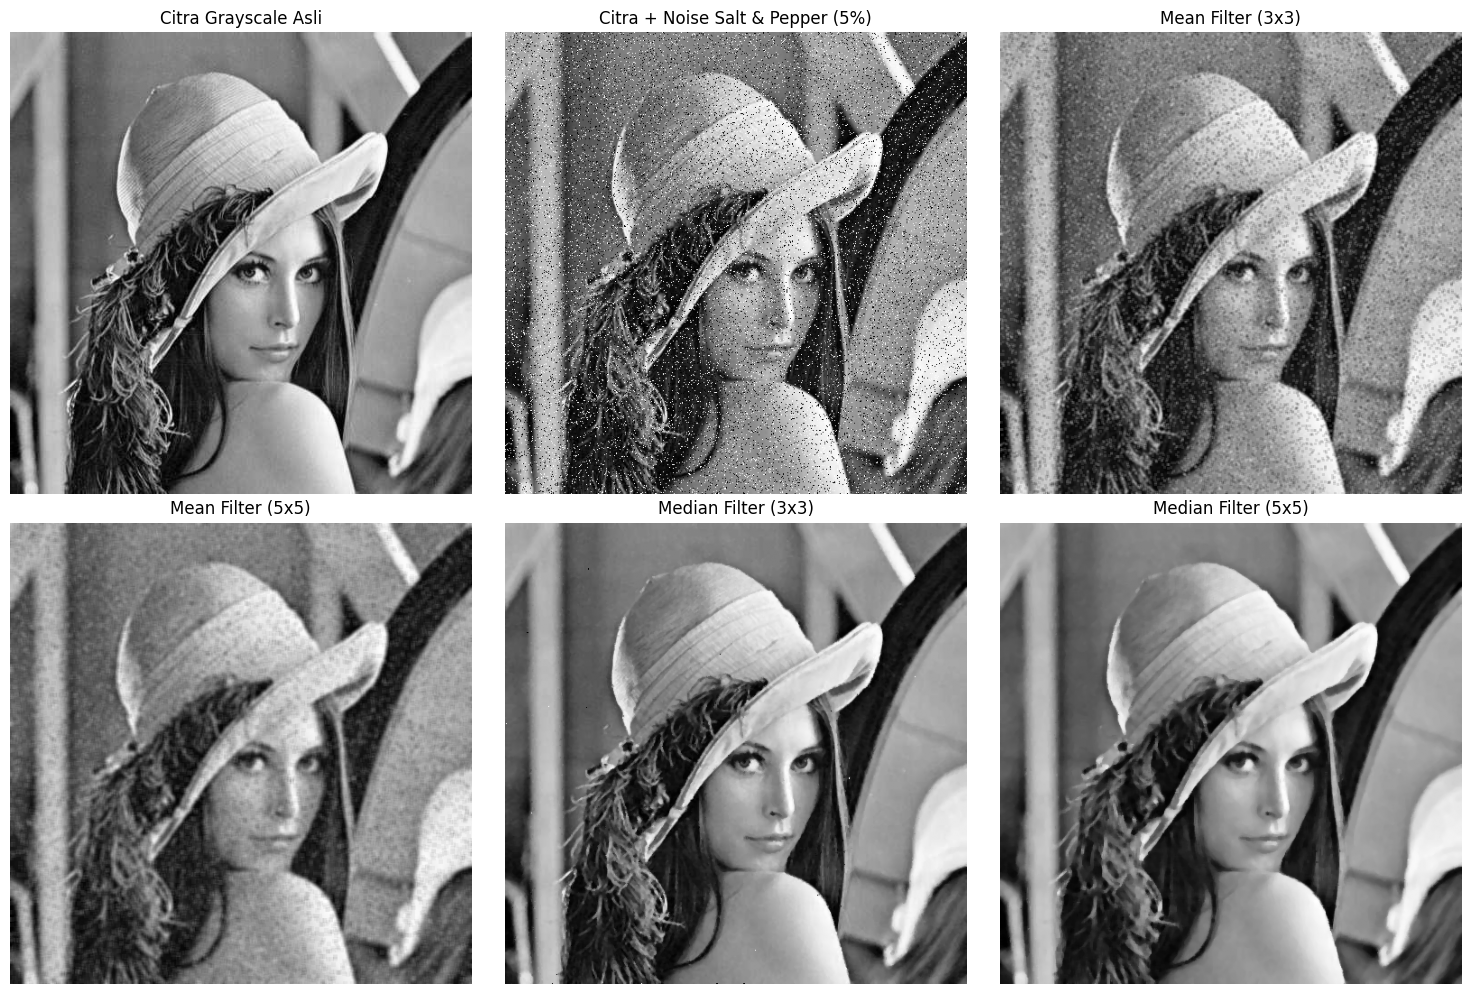

In [ ]:
# 1. Menerapkan Mean Filter (Filter Rata-rata) dengan kernel ukuran 3x3 dan 5x5
mean_3x3 = cv.blur(img_noisy, (3, 3))
mean_5x5 = cv.blur(img_noisy, (5, 5))

# 2. Menerapkan Median Filter dengan kernel ukuran 3x3 dan 5x5
median_3x3 = cv.medianBlur(img_noisy, 3)
median_5x5 = cv.medianBlur(img_noisy, 5)

# Menampilkan hasil menggunakan Matplotlib agar dapat dibandingkan secara berdampingan
plt.figure(figsize=(15, 10))

# Baris 1: Citra Asli, Noisy, dan Mean Filter
plt.subplot(2, 3, 1)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Grayscale Asli')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(img_noisy, cmap='gray')
plt.title('Citra + Noise Salt & Pepper (5%)')
plt.axis('off')

# Baris 2: Hasil Filtering
plt.subplot(2, 3, 3)
plt.imshow(mean_3x3, cmap='gray')
plt.title('Mean Filter (3x3)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(mean_5x5, cmap='gray')
plt.title('Mean Filter (5x5)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(median_3x3, cmap='gray')
plt.title('Median Filter (3x3)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(median_5x5, cmap='gray')
plt.title('Median Filter (5x5)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Analisis dan Penjelasan:

1. **Mean Filter (Filter Rata-rata)**:
   - Cara kerja: Mengganti nilai piksel dengan rata-rata nilai tetangganya sesuai ukuran kernel (misal $3 \times 3$).
   - Hasil: Citra menjadi lebih halus (blur), namun noise *salt & pepper* tidak sepenuhnya hilang melainkan hanya memudar atau menjadi kabur abu-abu karena nilai ekstrem hitam (0) dan putih (255) ikut dirata-ratakan ke dalam piksel sekitar.

2. **Median Filter**:
   - Cara kerja: Mengurutkan nilai piksel tetangga lalu mengambil nilai tengah (median)-nya.
   - Hasil: Sangat bersih! Noise *salt & pepper* (yang merupakan nilai ekstrem minimum/maksimum) akan tereliminasi sepenuhnya karena nilai ekstrem tersebut tidak akan pernah terpilih sebagai nilai median. Batas objek (edge) pada citra juga tetap terjaga dengan baik dibanding Mean Filter.

### 2. Tugas Evaluasi: Pemilihan Ukuran Kernel Terbaik untuk Menajamkan Citra (Sharpening)

Langkah-langkah:
1. Membuat citra asli menjadi sedikit buram (*blurry*) menggunakan Gaussian Blur.
2. Mendefinisikan **Sharpening Kernel 3x3** dan **5x5** secara manual.
3. Mengaplikasikan kernel penajaman tersebut dengan fungsi `cv.filter2D()`.
4. Memvisualisasikan perbandingan untuk evaluasi kejelasan tepi versus efek noise.

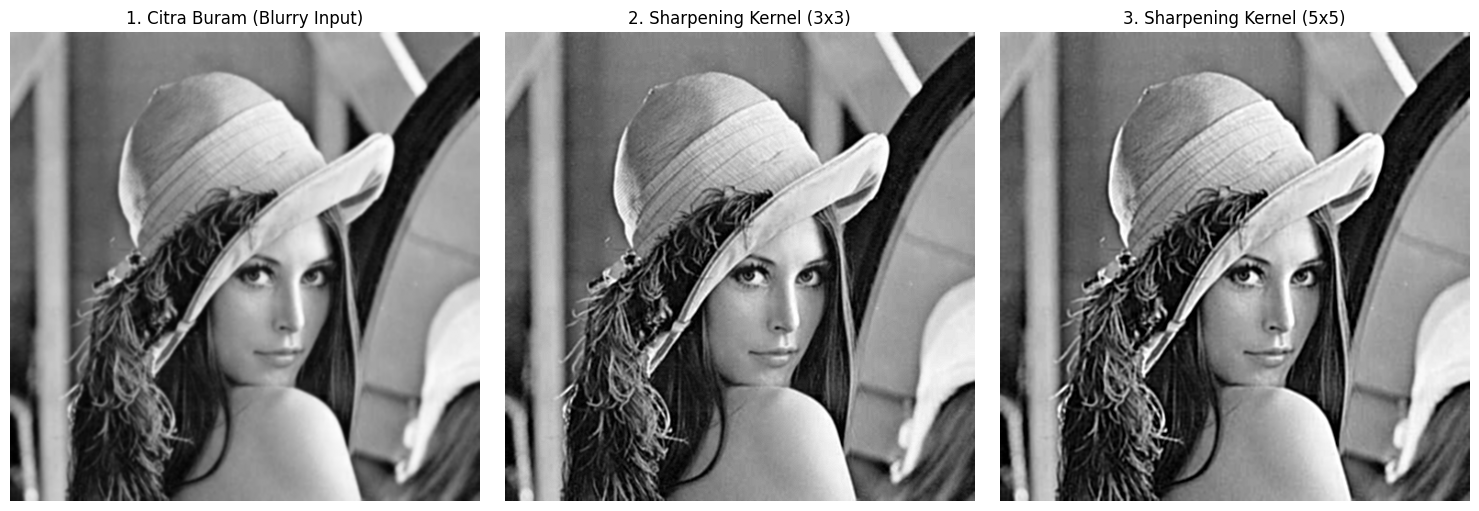

In [ ]:
# 1. Membuat citra menjadi sedikit buram (blurry image)
img_blurry = cv.GaussianBlur(img_gray, (5, 5), 0)

# 2. Mendefinisikan Sharpening Kernel 3x3
# Kernel standar penajaman (laplacian-based)
kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
])

# 3. Mendefinisikan Sharpening Kernel 5x5
# Kernel 5x5 dirancang untuk meningkatkan kontras tepi dengan radius lebih lebar
kernel_sharpen_5x5 = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1]
]) / 8.0  # Normalisasi agar kecerahan citra stabil

# 4. Menerapkan konvolusi dengan filter2D
img_sharpen_3x3 = cv.filter2D(img_blurry, -1, kernel_sharpen_3x3)
img_sharpen_5x5 = cv.filter2D(img_blurry, -1, kernel_sharpen_5x5)

# 5. Visualisasi Perbandingan
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_blurry, cmap='gray')
plt.title('1. Citra Buram (Blurry Input)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_sharpen_3x3, cmap='gray')
plt.title('2. Sharpening Kernel (3x3)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_sharpen_5x5, cmap='gray')
plt.title('3. Sharpening Kernel (5x5)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Evaluasi Hasil (Tugas 2):

- **Kernel 3x3**:
  - **Kejelasan Tepi**: Sangat tajam secara lokal, memberikan detail transisi piksel yang rapat dan kontras tepi yang tegas.
  - **Noise Distortion**: Distorsi noise yang dihasilkan sangat minim dan terkontrol karena area operasi tetangga piksel sempit.

- **Kernel 5x5**:
  - **Kejelasan Tepi**: Menghasilkan efek penajaman berskala lebih luas, namun batas tepi cenderung menghasilkan efek lingkaran bayangan (*halo effect*) atau garis putih yang terlalu tebal di sekitar objek.
  - **Noise Distortion**: Distorsi noise yang dihasilkan jauh lebih tinggi. Area rata-rata yang luas juga cenderung menonjolkan tekstur kasar secara berlebihan yang mengganggu detail halus.

- **Rekomendasi Optimal**: **Kernel 3x3** adalah pilihan paling optimal untuk penggunaan sehari-hari karena menghasilkan citra yang tajam alami tanpa memperkuat noise lokal secara berlebihan (*high frequency noise artifacts*).

### 3. Tugas Kreasi: Filter Kartun Sederhana (`kartun(image)`)

Fungsi kustom di bawah ini menggabungkan penghalusan warna berbasis **Bilateral Filter** dengan sketsa garis tepi dinamis berbasis **Adaptive Thresholding**.

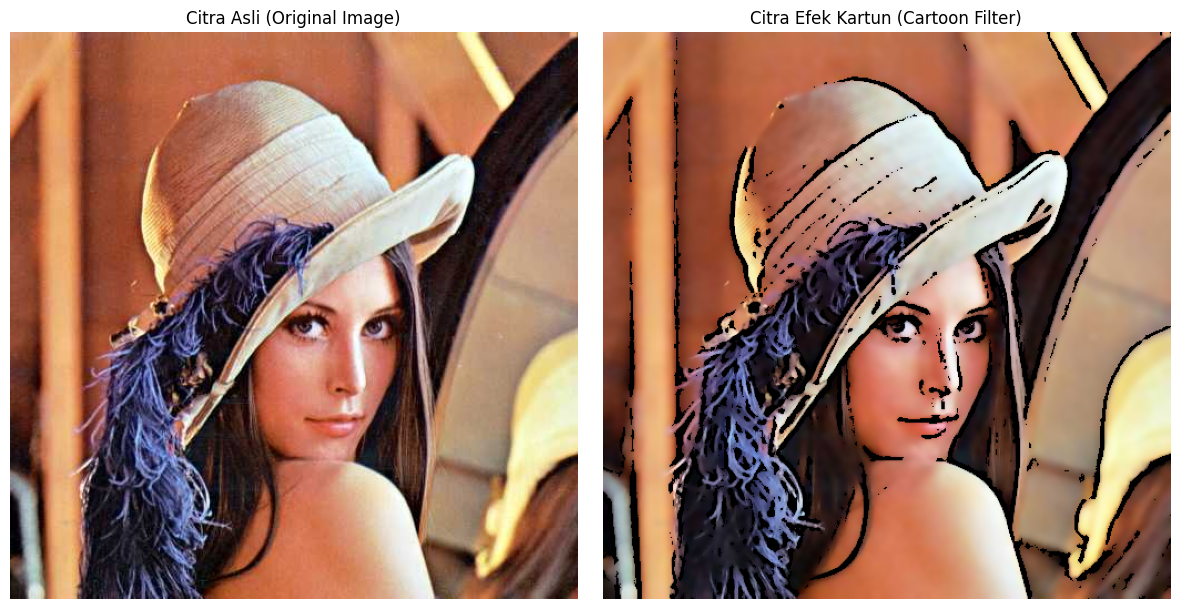

In [ ]:
def kartun(image):
    # Pastikan citra dalam format RGB/BGR (bukan grayscale untuk hasil kartun berwarna)
    if len(image.shape) < 3:
        # Jika input grayscale, konversi dulu ke BGR untuk pewarnaan bilateral
        image_color = cv.cvtColor(image, cv.COLOR_GRAY2BGR)
    else:
        image_color = image.copy()

    # 1. Penghalusan warna menggunakan Bilateral Filter
    # d=9 (diameter tetangga), sigmaColor=75, sigmaSpace=75
    color_smoothed = cv.bilateralFilter(image_color, d=9, sigmaColor=75, sigmaSpace=75)

    # 2. Deteksi garis tepi menggunakan Adaptive Thresholding
    # Konversi ke grayscale untuk menghitung threshold tepi
    gray = cv.cvtColor(image_color, cv.COLOR_BGR2GRAY)
    gray_blurred = cv.medianBlur(gray, 5) # Mengurangi noise halus sebelum deteksi tepi

    # Menghasilkan garis tepi hitam di atas latar belakang putih
    edges = cv.adaptiveThreshold(
        gray_blurred, 255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        blockSize=9,
        C=9
    )

    # Konversi edges ke 3 channel (BGR) agar bisa dipadukan dengan citra berwarna
    edges_color = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)

    # 3. Penggabungan menggunakan operasi logika Bitwise AND
    cartoon_result = cv.bitwise_and(color_smoothed, edges_color)

    return cartoon_result

# Membaca citra asli dalam format warna (BGR)
img_original_color = cv.imread('/content/drive/MyDrive/Colab Notebooks/lena.jpeg')

# Menerapkan filter kartun
img_cartoon = kartun(img_original_color)

# Mengonversi format warna dari BGR ke RGB untuk visualisasi Matplotlib yang tepat
img_original_rgb = cv.cvtColor(img_original_color, cv.COLOR_BGR2RGB)
img_cartoon_rgb = cv.cvtColor(img_cartoon, cv.COLOR_BGR2RGB)

# Visualisasi perbandingan bersebelahan
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_original_rgb)
plt.title('Citra Asli (Original Image)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_cartoon_rgb)
plt.title('Citra Efek Kartun (Cartoon Filter)')
plt.axis('off')

plt.tight_layout()
plt.show()

### Penjelasan Teknis Filter Kartun:
1. **Bilateral Filter**: Filter ini sangat unik karena menghitung bobot piksel tidak hanya berdasarkan jarak spasial (seperti Gaussian blur biasa), tetapi juga perbedaan intensitas warna. Hal ini membuat gradasi kulit dan latar belakang tereduksi menjadi blok-blok warna yang datar layaknya gambar lukisan atau kartun, tanpa mengaburkan batas tegas antar objek.
2. **Adaptive Thresholding**: Berbeda dengan thresholding statis, metode adaptif menentukan nilai ambang batas secara lokal (piksel demi piksel). Hasilnya adalah garis luar (outline/sketsa) hitam yang tajam dan dinamis di sekeliling fitur wajah (seperti mata, hidung, topi).
3. **Operasi Bitwise AND**: Dengan mengalikan atau memadukan sketsa hitam-putih tersebut dengan citra berwarna hasil Bilateral Filter, kita mendapatkan efek kartun yang hidup dengan warna datar yang terbingkai oleh outline hitam yang estetik.

### 4. Percobaan 6: Filter Malam (Night Filter)

Filter malam mensimulasikan pencahayaan minim dengan menurunkan kecerahan (*brightness*) citra serta memberikan nuansa warna biru (*cool/blue tone*).

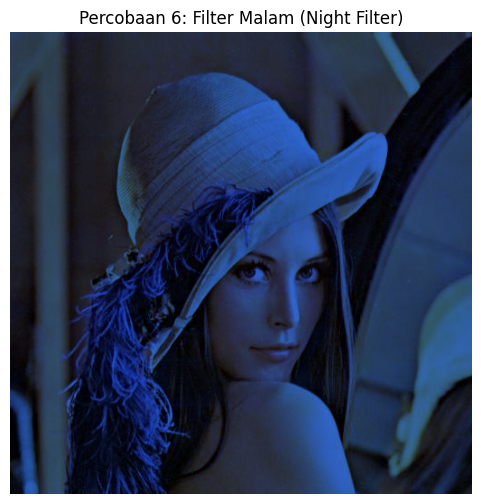

In [ ]:
def filter_malam(image):
    # Membuat duplikat citra asli
    img_temp = image.copy().astype(np.float32)

    # Memisahkan channel warna B, G, R
    b, g, r = cv.split(img_temp)

    # Memberikan nuansa biru malam: kurangi intensitas merah (R) dan hijau (G)
    r = r * 0.2
    g = g * 0.4
    b = b * 0.8

    # Menggabungkan kembali channel warna
    night_img = cv.merge([b, g, r])

    # Memastikan nilai piksel berada dalam rentang valid [0, 255]
    night_img = np.clip(night_img, 0, 255).astype(np.uint8)
    return night_img

# Menerapkan filter malam
img_malam = filter_malam(img_original_color)

# Konversi ke RGB untuk Matplotlib
img_malam_rgb = cv.cvtColor(img_malam, cv.COLOR_BGR2RGB)

# Menampilkan hasil
plt.figure(figsize=(6, 6))
plt.imshow(img_malam_rgb)
plt.title('Percobaan 6: Filter Malam (Night Filter)')
plt.axis('off')
plt.show()

### 5. Percobaan 7: Filter Pagi (Morning Filter) & Efek Kabut (Fog Effect)

Filter pagi memberikan nuansa hangat kekuningan (*warm tone*), sedangkan efek kabut disimulasikan dengan mencampur citra dengan warna putih menggunakan teknik *blending* (`cv.addWeighted()`).

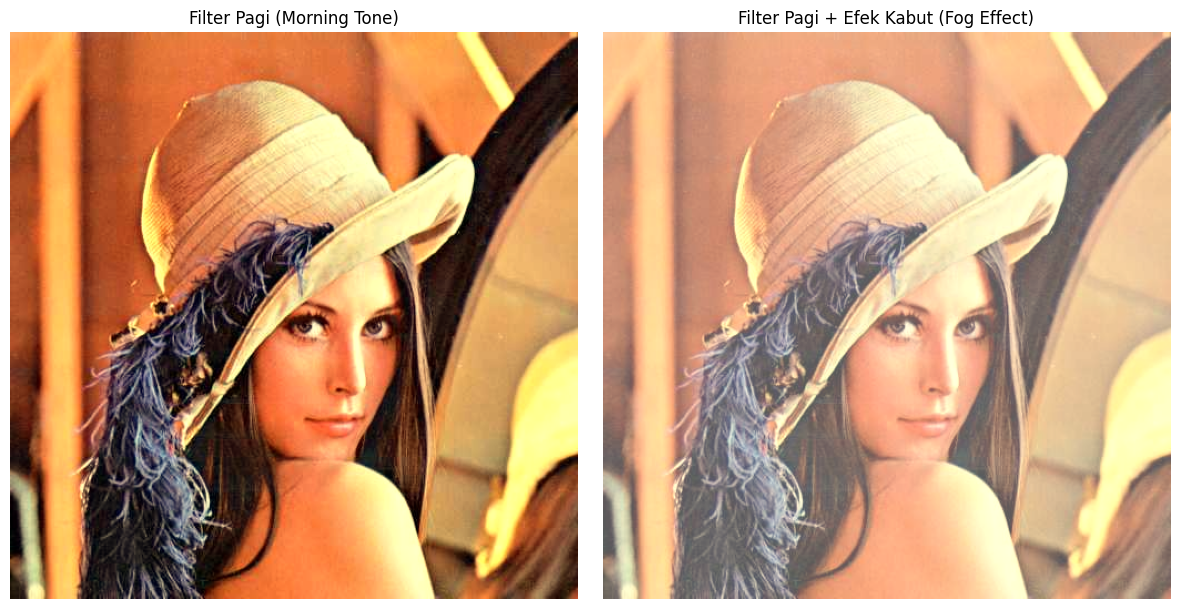

In [ ]:
def filter_pagi(image):
    img_temp = image.copy().astype(np.float32)
    b, g, r = cv.split(img_temp)

    # Memberikan nuansa pagi hangat: tingkatkan merah (R) dan hijau (G/kuning)
    r = r * 1.2
    g = g * 1.1
    b = b * 0.8

    morning_img = cv.merge([b, g, r])
    return np.clip(morning_img, 0, 255).astype(np.uint8)

def tambah_kabut(image, intensitas=0.4):
    # Membuat citra putih polos dengan ukuran yang sama
    putih = np.full(image.shape, 255, dtype=np.uint8)

    # Melakukan blending citra dengan warna putih untuk menyimulasikan kabut
    img_kabut = cv.addWeighted(image, 1 - intensitas, putih, intensitas, 0)
    return img_kabut

# Menerapkan filter
img_pagi = filter_pagi(img_original_color)
img_pagi_kabut = tambah_kabut(img_pagi, intensitas=0.35)

# Konversi ke RGB untuk visualisasi
img_pagi_rgb = cv.cvtColor(img_pagi, cv.COLOR_BGR2RGB)
img_pagi_kabut_rgb = cv.cvtColor(img_pagi_kabut, cv.COLOR_BGR2RGB)

# Visualisasi perbandingan
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_pagi_rgb)
plt.title('Filter Pagi (Morning Tone)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_pagi_kabut_rgb)
plt.title('Filter Pagi + Efek Kabut (Fog Effect)')
plt.axis('off')

plt.tight_layout()
plt.show()